<a href="https://colab.research.google.com/github/ali-akbar-bermano/Lecture-series_ALI-AKBAR-BERMANO_G1A024041/blob/main/implementasi_lecture_series_pertemuan_4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Prediksi Kelayakan Pinjaman / Kredit Bank (Klasifikasi — Supervised Learning)**

1. Import Module / Library

In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Sklearn Modules for ML Pipeline
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, precision_score, recall_score, f1_score

print("✅ Sel 1: Semua modul dan library berhasil diimpor!")

✅ Sel 1: Semua modul dan library berhasil diimpor!


2. Data Generation & Loading

In [2]:
# SEL 2: PEMBUATAN / LOADING DATASET
def load_loan_dataset(n_samples=1000, random_state=42):
    """
    Membuat dataset sintetis pengajuan kredit/pinjaman bank
    berdasarkan fitur riwayat keuangan nasabah.
    """
    np.random.seed(random_state)

    # Generasi Atribut/Fitur
    study_hours = np.random.uniform(1, 10, n_samples)
    income = np.random.normal(5000, 1500, n_samples)          # Pendapatan bulanan ($)
    credit_score = np.random.randint(300, 850, n_samples)     # Skor Kredit
    loan_amount = np.random.uniform(5000, 50000, n_samples)   # Jumlah Pinjaman ($)
    debt_ratio = np.random.uniform(0.1, 0.8, n_samples)       # Rasio Utang
    employment_status = np.random.choice(['Employed', 'Self-Employed', 'Unemployed'], size=n_samples, p=[0.7, 0.2, 0.1])
    credit_history = np.random.choice([0, 1], size=n_samples, p=[0.2, 0.8]) # 1: Baik, 0: Buruk

    # Logika Penentuan Target (1: Approved, 0: Rejected)
    score_formula = (
        (income / 1000) * 0.3 +
        (credit_score / 100) * 0.4 +
        credit_history * 2.5 -
        debt_ratio * 2.0 -
        (employment_status == 'Unemployed') * 3.0
    )

    loan_status = np.where(score_formula > 3.2, 'Approved', 'Rejected')

    # Konversi ke Pandas DataFrame
    df = pd.DataFrame({
        'Income': np.round(income, 2),
        'CreditScore': credit_score,
        'LoanAmount': np.round(loan_amount, 2),
        'DebtRatio': np.round(debt_ratio, 2),
        'EmploymentStatus': employment_status,
        'CreditHistory': credit_history,
        'LoanStatus': loan_status
    })

    # Simulasi Missing Values (untuk pengujian Data Cleaning)
    df.loc[df.sample(frac=0.03, random_state=42).index, 'Income'] = np.nan
    df.loc[df.sample(frac=0.02, random_state=101).index, 'DebtRatio'] = np.nan

    return df

# Memuat dataset ke variabel df_loan
df_loan = load_loan_dataset()
print("✅ Sel 2: Dataset berhasil dimuat!")
print(f"Jumlah sampel data: {df_loan.shape[0]} baris, {df_loan.shape[1]} kolom\n")
print(df_loan.head())

✅ Sel 2: Dataset berhasil dimuat!
Jumlah sampel data: 1000 baris, 7 kolom

    Income  CreditScore  LoanAmount  DebtRatio EmploymentStatus  \
0  5266.55          748    15869.16       0.36         Employed   
1  2996.98          740    20942.21       0.55    Self-Employed   
2  5570.30          392     9740.55       0.43         Employed   
3  5915.88          723    15006.26       0.23         Employed   
4  5839.69          441    28365.11       0.59         Employed   

   CreditHistory LoanStatus  
0              0   Approved  
1              1   Approved  
2              1   Approved  
3              1   Approved  
4              1   Approved  


3. Data Preprocessing & Cleaning

In [3]:
# SEL 3: DATA PREPROCESSING & DATA SPLITTING
def preprocess_and_split_data(df, target_col='LoanStatus', test_size=0.2, random_state=42):
    """
    Menangani missing values, encoding data kategorikal,
    dan melakukan train-test split.
    """
    df_clean = df.copy()

    # 1. Handling Missing Values (Mengisi dengan Median)
    df_clean['Income'].fillna(df_clean['Income'].median(), inplace=True)
    df_clean['DebtRatio'].fillna(df_clean['DebtRatio'].median(), inplace=True)

    # 2. Encoding Variable Kategorikal
    le_emp = LabelEncoder()
    df_clean['EmploymentStatus'] = le_emp.fit_transform(df_clean['EmploymentStatus'])

    le_target = LabelEncoder()
    df_clean[target_col] = le_target.fit_transform(df_clean[target_col]) # Approved: 0, Rejected: 1 (atau sebaliknya)

    # 3. Pemisahan Feature (X) dan Target Label (y)
    X = df_clean.drop(columns=[target_col])
    y = df_clean[target_col]

    # 4. Data Splitting (80% Train, 20% Test)
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=test_size, random_state=random_state, stratify=y
    )

    # 5. Normalisasi Feature Scaling (StandardScaler)
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)

    return X_train_scaled, X_test_scaled, y_train, y_test, scaler, le_target

# Eksekusi Preprocessing
X_train, X_test, y_train, y_test, scaler, label_encoder = preprocess_and_split_data(df_loan)
print("✅ Sel 3: Data Preprocessing & Split Selesai!")
print(f"Jumlah Data Training : {X_train.shape[0]} data")
print(f"Jumlah Data Testing  : {X_test.shape[0]} data")

✅ Sel 3: Data Preprocessing & Split Selesai!
Jumlah Data Training : 800 data
Jumlah Data Testing  : 200 data


/tmp/ipykernel_2980/3910417110.py:10: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df_clean['Income'].fillna(df_clean['Income'].median(), inplace=True)
/tmp/ipykernel_2980/3910417110.py:11: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value

4. Model Training (Pelatihan Model ML)

In [4]:
# SEL 4: MODEL TRAINING
def train_classification_models(X_train, y_train, random_state=42):
    """
    Melatih dua model klasifikasi Machine Learning.
    """
    models = {
        'Logistic Regression': LogisticRegression(random_state=random_state),
        'Decision Tree': DecisionTreeClassifier(max_depth=5, random_state=random_state)
    }

    trained_models = {}
    for name, model in models.items():
        model.fit(X_train, y_train)
        trained_models[name] = model
        print(f"   > Model '{name}' berhasil dilatih.")

    return trained_models

print("✅ Sel 4: Melatih Model Machine Learning...")
trained_models = train_classification_models(X_train, y_train)

✅ Sel 4: Melatih Model Machine Learning...
   > Model 'Logistic Regression' berhasil dilatih.
   > Model 'Decision Tree' berhasil dilatih.


5. Model Evaluation & Metrics Analysis

=== PERFORMA MODEL: LOGISTIC REGRESSION ===
Akurasi   : 94.50%
Precision : 0.9091
Recall    : 0.7895
F1-Score  : 0.8451

=== PERFORMA MODEL: DECISION TREE ===
Akurasi   : 95.50%
Precision : 0.8537
Recall    : 0.9211
F1-Score  : 0.8861



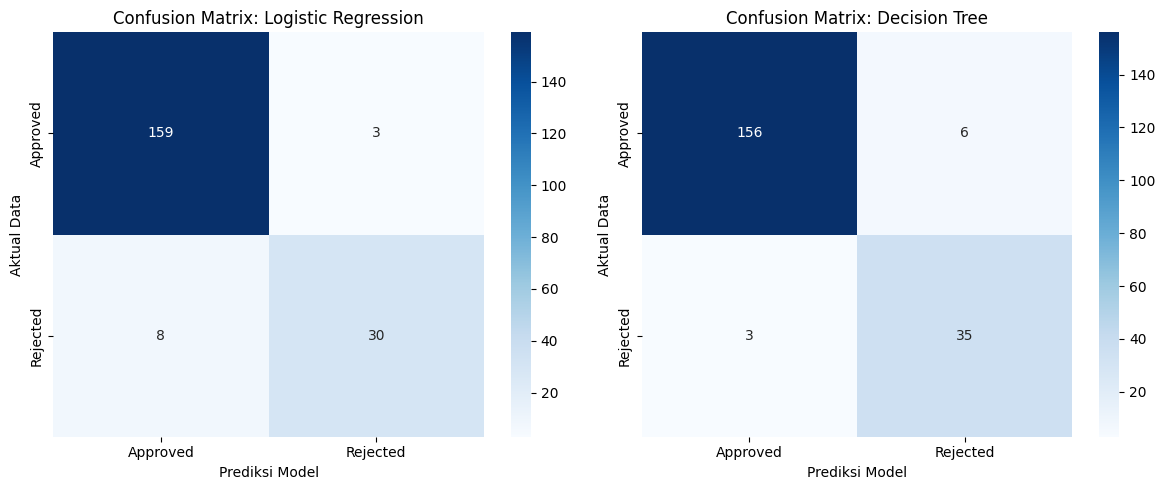

In [5]:
# SEL 5: EVALUASI MODEL MACHINE LEARNING
def evaluate_models(models, X_test, y_test, target_labels):
    """
    Mengevaluasi akurasi dan menampilkan Confusion Matrix dari model.
    """
    fig, axes = plt.subplots(1, len(models), figsize=(12, 5))

    for idx, (name, model) in enumerate(models.items()):
        y_pred = model.predict(X_test)

        acc = accuracy_score(y_test, y_pred)
        prec = precision_score(y_test, y_pred)
        rec = recall_score(y_test, y_pred)
        f1 = f1_score(y_test, y_pred)

        print(f"=== PERFORMA MODEL: {name.upper()} ===")
        print(f"Akurasi   : {acc * 100:.2f}%")
        print(f"Precision : {prec:.4f}")
        print(f"Recall    : {rec:.4f}")
        print(f"F1-Score  : {f1:.4f}\n")

        # Heatmap Confusion Matrix
        cm = confusion_matrix(y_test, y_pred)
        sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[idx],
                    xticklabels=target_labels, yticklabels=target_labels)
        axes[idx].set_title(f'Confusion Matrix: {name}')
        axes[idx].set_xlabel('Prediksi Model')
        axes[idx].set_ylabel('Aktual Data')

    plt.tight_layout()
    plt.show()

# Menjalankan Evaluasi
target_class_names = label_encoder.classes_
evaluate_models(trained_models, X_test, y_test, target_class_names)

6. Inference Function (Prediksi Data Nasabah Baru)

In [6]:
# SEL 6: PREDIKSI UNTUK NASABAH BARU
def predict_new_applicant(model, scaler, label_encoder, new_data):
    """
    Fungsi untuk memprediksi kelayakan pinjaman dari nasabah baru.
    """
    # Convert data baru ke DataFrame
    df_new = pd.DataFrame([new_data])

    # Preprocessing ringan (Encoding manual untuk Status Pekerjaan)
    emp_map = {'Employed': 0, 'Self-Employed': 1, 'Unemployed': 2}
    df_new['EmploymentStatus'] = df_new['EmploymentStatus'].map(emp_map)

    # Scaling
    new_scaled = scaler.transform(df_new)

    # Prediksi
    pred_code = model.predict(new_scaled)[0]
    pred_label = label_encoder.inverse_transform([pred_code])[0]

    return pred_label

# --- UJI COBA INPUT DATA NASABAH BARU ---
sample_applicant = {
    'Income': 6500.00,
    'CreditScore': 720,
    'LoanAmount': 15000.00,
    'DebtRatio': 0.25,
    'EmploymentStatus': 'Employed',
    'CreditHistory': 1
}

best_model = trained_models['Logistic Regression']
hasil_prediksi = predict_new_applicant(best_model, scaler, label_encoder, sample_applicant)

print("=== HASIL PREDIKSI KELAYAKAN PINJAMAN ===")
print("Data Nasabah Baru:", sample_applicant)
print(f"Status Kelayakan Pinjaman: *** {hasil_prediksi.upper()} ***")

=== HASIL PREDIKSI KELAYAKAN PINJAMAN ===
Data Nasabah Baru: {'Income': 6500.0, 'CreditScore': 720, 'LoanAmount': 15000.0, 'DebtRatio': 0.25, 'EmploymentStatus': 'Employed', 'CreditHistory': 1}
Status Kelayakan Pinjaman: *** APPROVED ***
